# 1. Import Libraries

In [34]:
import pandas as pd
import numpy as ny
import seaborn as sns
import matplotlib.pyplot as plt

In [40]:
df = pd.read_csv(r"D:\Dataset_for_projects\oil_production_statistics.csv",encoding="latin1")

df.head()

,country_name,type,product,flow,year,value
0,Australia,Balance,Crude oil,Industrial Production,2021,18029.678
1,Austria,Balance,Crude oil,Industrial Production,2021,561.852
2,Belgium,Balance,Crude oil,Industrial Production,2021,0.000
3,Canada,Balance,Crude oil,Industrial Production,2021,266630.180
4,Chile,Balance,Crude oil,Industrial Production,2021,340.997


In [32]:
df.shape

(2376, 6)

In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2376 entries, 0 to 2375
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   country_name  2376 non-null   str    
 1   type          2376 non-null   str    
 2   product       2376 non-null   str    
 3   flow          2376 non-null   str    
 4   year          2376 non-null   int64  
 5   value         2376 non-null   float64
dtypes: float64(1), int64(1), str(4)
memory usage: 111.5 KB


In [35]:
df.columns

Index(['country_name', 'type', 'product', 'flow', 'year', 'value'], dtype='str')

# 2. Check Dataset values for statistic

In [37]:
# Check the year range
print("Maximum year : ",df["year"].max())
print("Minimum year : ",df["year"].min())
print("Unique years : ",df["year"].nunique())


Maximum year :  2023
Minimum year :  2021
Unique years :  3


In [42]:
# Check avilable countries and products
print("Total Countries : ",df["country_name"].nunique())
print("Types: ",df["type"].nunique())
print("Total Products : ",df["product"].nunique())
print("Flows : ",df["flow"].nunique())

Total Countries :  36
Types:  1
Total Products :  11
Flows :  4


In [46]:
# Calculate Descriptive Statistics
print(df["value"].describe())

count      2376.000000
mean       6298.349414
std       36784.314385
min       -2442.000000
25%          48.559500
50%         462.107500
75%        2594.835250
max      790672.407000
Name: value, dtype: float64


In [52]:
# Check null values and duplictes 
print("Null Value counts :\n",df.isnull().sum())
print("\nDuplicate Value counts :\n",df.duplicated().sum())

Null Value counts :
 country_name    0
type            0
product         0
flow            0
year            0
value           0
dtype: int64

Duplicate Value counts :
 44


In [60]:
# Remove extract duplicated
df = df.drop_duplicates().reset_index(drop=True)

In [63]:
# No Dataset details
print("Shape of dataset : ",df.shape)
print("Duplicates : ",df.duplicated().sum())
print("Missing Values :\n",df.isnull().sum())

Shape of dataset :  (2332, 6)
Duplicates :  0
Missing Values :
 country_name    0
type            0
product         0
flow            0
year            0
value           0
dtype: int64


In [66]:
# Yearly counts
df["year"].value_counts().sort_index()

year
2021    1036
2022     540
2023     756
Name: count, dtype: int64

# 3. Descriptive staistics

In [78]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
year,2332.0,2021.88,0.87,2021.0,2021.0,2022.00,2023.00,2023.00
value,2332.0,6417.10,37119.60,-2442.0,56.0,503.82,2694.29,790672.41


# 4. Year wise statistical analysis

In [79]:
df.groupby("year")["value"].agg(["count", "mean", "median", "std", "min", "max"]).round(2)

,count,mean,median,std,min,max
year,,,,,,
2021,1036,11526.43,1396.27,54144.30,-34.97,790672.41
2022,540,2809.55,320.31,10931.53,-29.10,168007.00
2023,756,1992.24,102.09,9229.06,-2442.00,163841.00


In [81]:
df.columns

Index(['country_name', 'type', 'product', 'flow', 'year', 'value'], dtype='str')

# 5. Analyze production by products

In [88]:
prod = df.groupby("product")["value"].sum().sort_values(ascending=False)
print(prod) 

product
Total oil products production    4704037.226
Crude oil                        3836643.282
Total oil production             1891871.042
Total gas oil production         1427695.067
Gasoline and diesel              1348675.703
Other oil products                404803.150
Middle distillates                380232.157
Total kerosene production         347132.536
Naphtha                           261844.629
Liquified Petroleum Gas           215723.344
Residual fuel oil                 146021.072
Name: value, dtype: float64


# 6. Visualize products

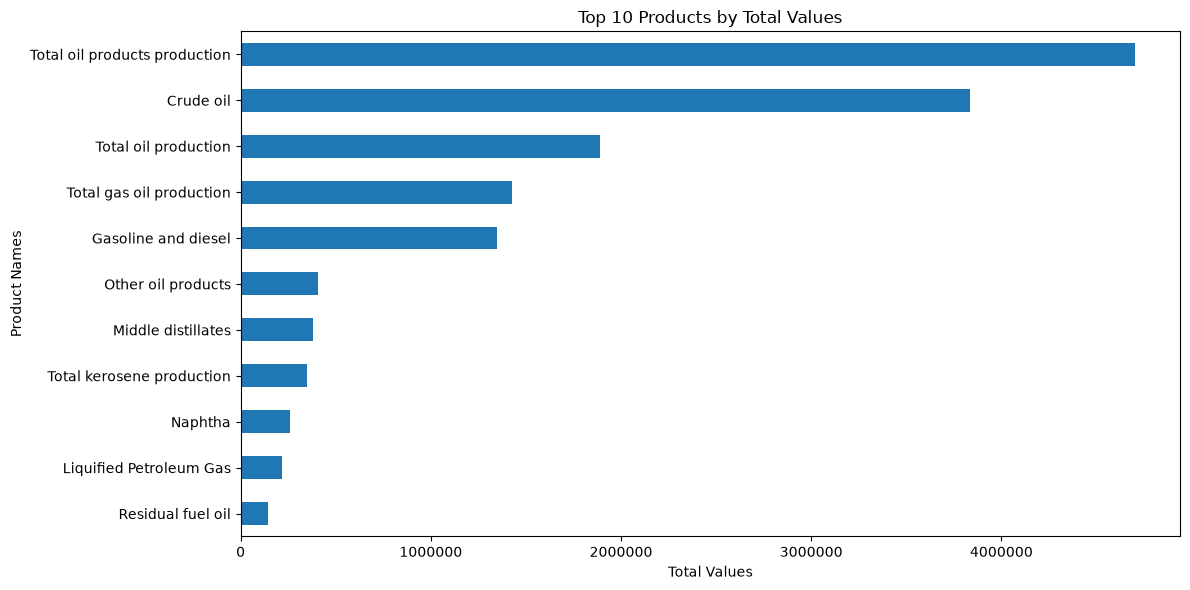

In [92]:
prod.sort_values().plot(kind="barh",figsize=(12,6))

plt.title("Top 10 Products by Total Values")
plt.xlabel("Total Values")
plt.ylabel("Product Names")
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()

# 7. Analyze the distribustion of production values

In [94]:
df["value"].describe()

count      2332.000000
mean       6417.100861
std       37119.601504
min       -2442.000000
25%          56.000000
50%         503.825000
75%        2694.294750
max      790672.407000
Name: value, dtype: float64

# 8. Detect outliers using the IQR method

In [95]:
Q1 = df["value"].quantile(0.25)
Q3 = df["value"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

outliers = df[(df["value"] < lower) | (df["value"] > upper)]

print("Lower limit : ",lower)
print("Upper limit : ",upper)
print("Numbers of outliers : ",len(outliers))

Lower limit :  -3901.442125
Upper limit :  6651.7368750000005
Numbers of outliers :  308


# 9. Visualize using Boxplot

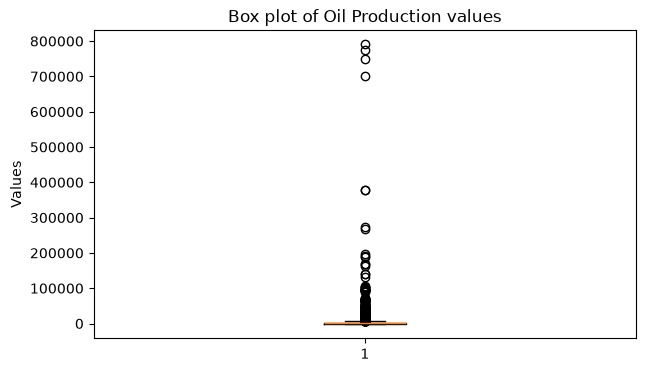

In [101]:
plt.figure(figsize=(7,4))
plt.boxplot(df["value"].dropna())

plt.title("Box plot of Oil Production values")
plt.ylabel("Values")
plt.show()

# 10. Countrywise Statical analysis

In [105]:
country_stats = df.groupby("country_name")["value"].agg(["count", "mean", "median", "std", "min", "max"]).round(2)

country_stats.sort_values("mean", ascending=False)

,count,mean,median,std,min,max
country_name,,,,,,
United States,66,99389.76,22834.50,185441.82,-2442.00,790672.41
Japan,66,17864.80,4807.16,29404.46,-937.57,140635.37
Canada,66,17466.28,2600.77,48295.43,-396.65,274365.89
Germany,66,11385.02,3411.19,18595.78,-67.83,93776.83
South Korea,66,9492.54,2523.57,17817.19,-219.83,95522.76
France,66,7784.85,3063.00,13865.24,-248.00,69994.00
Mexico,66,7532.26,2112.00,18780.11,-167.00,95823.00
United Kingdom,66,6317.61,2512.50,12044.60,-131.00,58678.35
Italy,66,5816.84,2894.43,9607.19,-86.84,49825.24


# 11. Analyze yearly trend

In [108]:
yearly = df.groupby("year")["value"].sum()
print(yearly)

year
2021    1.194139e+07
2022    1.517158e+06
2023    1.506135e+06
Name: value, dtype: float64


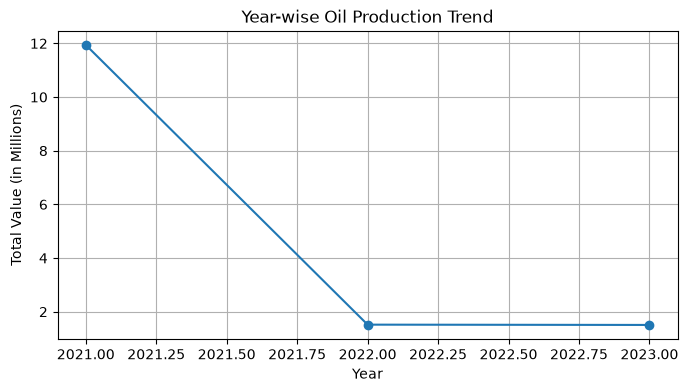

In [111]:
# Visualisation
yearly = yearly / 1000000
fig = yearly.plot(kind="line", marker = "o", figsize=(8,4))

plt.title("Year-wise Oil Production Trend")
plt.xlabel("Year")
plt.ylabel("Total Value (in Millions)")
plt.grid(True)
plt.show()

# 12. Yearwise Growth Rate

In [112]:
growth = yearly.pct_change()*100

print(growth.round(2))

year
2021      NaN
2022   -87.29
2023    -0.73
Name: value, dtype: float64


# 13. Analyze production by types

In [113]:
type_stats = df.groupby("type")["value"].agg(["count", "mean", "median", "std", "min", "max"]).round(2)

type_stats.sort_values("mean", ascending=False)

,count,mean,median,std,min,max
type,,,,,,
Balance,2332,6417.1,503.82,37119.6,-2442.0,790672.41


# 13. Analyze production by flows

In [114]:
flow_stats = df.groupby("flow")["value"].agg(["count", "mean", "median", "std", "min", "max"]).round(2)

flow_stats.sort_values("mean", ascending=False)

,count,mean,median,std,min,max
flow,,,,,,
Industrial Production,132,20891.65,79.55,95495.36,0.00,749969.00
Net Deliveries,1139,6832.51,456.00,39287.68,-34.97,790672.41
Consumption Pattern,845,5232.98,1184.04,16244.49,0.00,197026.00
Storage Channelization,216,13.37,0.46,346.07,-2442.00,2143.00


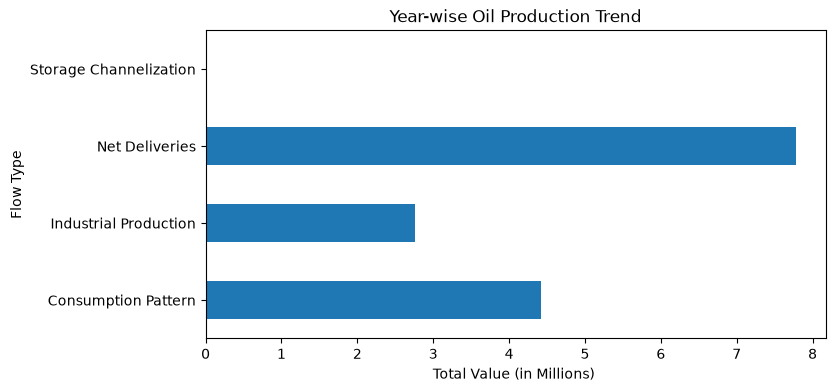

In [118]:
# Visualize 
flow_total = df.groupby("flow")["value"].sum()
flow_total = flow_total / 1000000
fig = flow_total.plot(kind="barh",figsize=(8,4))

plt.title("Year-wise Oil Production Trend")
plt.xlabel("Total Value (in Millions) ")
plt.ylabel("Flow Type")
plt.show()

# 14. Correlation Anaysis

In [119]:
df.corr(numeric_only = True)

,year,value
year,1.000000,-0.114949
value,-0.114949,1.000000


# Final Conclusion – Oil Production Statistical Analysis

## Project Summary

The purpose of this project was to analyze oil production data and identify patterns, variations, and differences across products, countries, years, and flow categories. Python was used to organize the data, calculate statistical measures, and present the findings through charts and tables.

## Key Findings

1. **Product Analysis:** Total oil products production recorded the highest aggregate value among the product categories analyzed.

2. **Country Analysis:** The United States recorded the highest average value among the countries included in the dataset.

3. **Yearly Analysis:** The total recorded value was approximately 11.94 million in 2021, 1.52 million in 2022, and 1.51 million in 2023.

4. **Yearly Changes:** The total recorded value decreased by approximately 87.29% in 2022 and 0.73% in 2023 compared with the preceding year.

5. **Outlier Analysis:** The statistical assessment identified 308 observations outside the expected range calculated using the IQR method. These observations require further review to determine whether they represent genuine extreme values or data issues.

6. **Flow Analysis:** Industrial Production had the highest average recorded value, while Net Deliveries accounted for the largest number of records.

7. **Correlation Analysis:** The relationship between year and recorded value was weak and negative, with a correlation coefficient of −0.115.

## Conclusion

The analysis provided a clearer understanding of the distribution and variation of oil-production-related data. Statistical summaries and visualizations helped identify differences across product categories, countries, and flow types, as well as changes in recorded values over time.

The substantial decrease in the yearly total between 2021 and 2022 requires further investigation. Differences in data coverage, product categories, and flow classifications may influence these results. Therefore, the observed changes should not be interpreted as a direct measure of actual oil production without additional verification.

Overall, this project demonstrates the practical application of statistical analysis and data visualization to organize information, evaluate trends, and communicate findings for informed decision-making.